In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [324]:

train = pd.read_csv("../raw_data/train.csv")
test = pd.read_csv("../raw_data/test.csv")

In [325]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [326]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [327]:
columns = [col for col in train.columns if col not in ("Survived", "PassengerId")]
X = train[columns]
y = train["Survived"]
X_test = test[columns]
test_ids = test["PassengerId"]

In [328]:
X.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [329]:
# Видим пропуски в столбце Age
X.describe()

,Pclass,Age,SibSp,Parch,Fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,2.000000,20.125000,0.000000,0.000000,7.910400
50%,3.000000,28.000000,0.000000,0.000000,14.454200
75%,3.000000,38.000000,1.000000,0.000000,31.000000
max,3.000000,80.000000,8.000000,6.000000,512.329200


In [330]:
X.describe(include="object")

/var/folders/6n/xcr_g_3d13529x7vjx2_z7qc0000gn/T/ipykernel_74205/3236359428.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  X.describe(include="object")


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


In [331]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    891 non-null    int64  
 1   Name      891 non-null    str    
 2   Sex       891 non-null    str    
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Ticket    891 non-null    str    
 7   Fare      891 non-null    float64
 8   Cabin     204 non-null    str    
 9   Embarked  889 non-null    str    
dtypes: float64(2), int64(3), str(5)
memory usage: 69.7 KB


In [332]:
X["Sex"].value_counts()

Sex
male      577
female    314
Name: count, dtype: int64

In [333]:
X["Sex"] = X["Sex"].map({"male": 1, "female": 0})
X_test["Sex"] = X_test["Sex"].map({"male": 1, "female": 0})

In [334]:
X["Sex"].sum()

np.int64(577)

In [335]:
X.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,C85,C
2,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,C123,S
4,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,NaN,S


In [336]:
X = X.drop("Name", axis=1)
X_test = X_test.drop("Name", axis=1)

X = X.drop("Ticket", axis=1)
X_test = X_test.drop("Ticket", axis=1)

X = X.drop("Cabin", axis=1)
X_test = X_test.drop("Cabin", axis=1)

In [337]:
X["Embarked"].value_counts().count()

np.int64(3)

In [338]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

In [339]:
embarked_mode = X_train["Embarked"].mode()[0]
age_median = X_train["Age"].median()

In [340]:
X_train.fillna({"Embarked": embarked_mode, "Age": age_median}, inplace=True)
X_val.fillna({"Embarked": embarked_mode, "Age": age_median}, inplace=True)
X_test.fillna({"Embarked": embarked_mode, "Age": age_median}, inplace=True)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,34.5,0,0,7.8292,Q
1,3,0,47.0,1,0,7.0000,S
2,2,1,62.0,0,0,9.6875,Q
3,3,1,27.0,0,0,8.6625,S
4,3,0,22.0,1,1,12.2875,S
...,...,...,...,...,...,...,...
413,3,1,29.0,0,0,8.0500,S
414,1,0,39.0,0,0,108.9000,C
415,3,1,38.5,0,0,7.2500,S
416,3,1,29.0,0,0,8.0500,S


In [341]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 668 entries, 486 to 821
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    668 non-null    int64  
 1   Sex       668 non-null    int64  
 2   Age       668 non-null    float64
 3   SibSp     668 non-null    int64  
 4   Parch     668 non-null    int64  
 5   Fare      668 non-null    float64
 6   Embarked  668 non-null    str    
dtypes: float64(2), int64(4), str(1)
memory usage: 41.8 KB


In [342]:
X_val.info()

<class 'pandas.DataFrame'>
Index: 223 entries, 157 to 639
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    223 non-null    int64  
 1   Sex       223 non-null    int64  
 2   Age       223 non-null    float64
 3   SibSp     223 non-null    int64  
 4   Parch     223 non-null    int64  
 5   Fare      223 non-null    float64
 6   Embarked  223 non-null    str    
dtypes: float64(2), int64(4), str(1)
memory usage: 13.9 KB


In [343]:
X_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Pclass    418 non-null    int64  
 1   Sex       418 non-null    int64  
 2   Age       418 non-null    float64
 3   SibSp     418 non-null    int64  
 4   Parch     418 non-null    int64  
 5   Fare      417 non-null    float64
 6   Embarked  418 non-null    str    
dtypes: float64(2), int64(4), str(1)
memory usage: 23.0 KB


In [344]:
X_test.fillna({"Fare": X_train["Fare"].median()}, inplace=True)

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,1,34.5,0,0,7.8292,Q
1,3,0,47.0,1,0,7.0000,S
2,2,1,62.0,0,0,9.6875,Q
3,3,1,27.0,0,0,8.6625,S
4,3,0,22.0,1,1,12.2875,S
...,...,...,...,...,...,...,...
413,3,1,29.0,0,0,8.0500,S
414,1,0,39.0,0,0,108.9000,C
415,3,1,38.5,0,0,7.2500,S
416,3,1,29.0,0,0,8.0500,S


In [345]:
ohe = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
).set_output(transform="pandas")

encoded = ohe.fit_transform(X_train[["Embarked"]])
encoded_val = ohe.transform(X_val[["Embarked"]])
encoded_test = ohe.transform(X_test[["Embarked"]])

X_train = pd.concat([X_train.drop(columns="Embarked"), encoded], axis=1)
X_val = pd.concat([X_val.drop(columns="Embarked"), encoded_val], axis=1)
X_test = pd.concat([X_test.drop(columns="Embarked"), encoded_test], axis=1,)

In [346]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
486,1,0,35.0,1,0,90.000,0.0,0.0,1.0
238,2,1,19.0,0,0,10.500,0.0,0.0,1.0
722,2,1,34.0,0,0,13.000,0.0,0.0,1.0
184,3,0,4.0,0,2,22.025,0.0,0.0,1.0
56,2,0,21.0,0,0,10.500,0.0,0.0,1.0


In [347]:
scaler = StandardScaler()

scaler.fit(X_train)

X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_val = pd.DataFrame(scaler.transform(X_val), columns=X_train.columns, index=X_val.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns, index=X_test.index)

In [348]:
X_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
486,-1.579334,-1.361874,0.405333,0.536677,-0.451483,1.240397,-0.498596,-0.29656,0.623517
238,-0.376375,0.734282,-0.829764,-0.464720,-0.451483,-0.436028,-0.498596,-0.29656,0.623517
722,-0.376375,0.734282,0.328140,-0.464720,-0.451483,-0.383310,-0.498596,-0.29656,0.623517
184,0.826584,-1.361874,-1.987668,-0.464720,1.951631,-0.192999,-0.498596,-0.29656,0.623517
56,-0.376375,-1.361874,-0.675377,-0.464720,-0.451483,-0.436028,-0.498596,-0.29656,0.623517


In [349]:
X_test.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0.826584,0.734282,0.366737,-0.464720,-0.451483,-0.492347,-0.498596,3.371998,-1.603806
1,0.826584,-1.361874,1.331656,0.536677,-0.451483,-0.509833,-0.498596,-0.296560,0.623517
2,-0.376375,0.734282,2.489560,-0.464720,-0.451483,-0.453161,-0.498596,3.371998,-1.603806
3,0.826584,0.734282,-0.212215,-0.464720,-0.451483,-0.474776,-0.498596,-0.296560,0.623517
4,0.826584,-1.361874,-0.598183,0.536677,0.750074,-0.398335,-0.498596,-0.296560,0.623517


In [351]:
baseline_pred = pd.Series(
    y_train.mode()[0],
    index=y_val.index,
    name=y_val.name,
)

accuracy_score(y_val, baseline_pred)

0.6143497757847534

In [364]:
model = LogisticRegression()

model.fit(X_train, y_train)
pred = model.predict(X_val)
accuracy_score(y_val, pred)

0.7757847533632287

In [ ]:
test_pred = model.predict(X_test)

submission = pd.DataFrame({
    "PassengerId": test_ids.to_numpy(),
    "Survived": test_pred.ravel().astype(int),
})

submission.to_csv("../submission_logreg.csv", index=False)

In [ ]:
submission

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
...,...,...
413,1305,0
414,1306,1
415,1307,0
416,1308,0


In [ ]:
submission.to_csv("../submission_logreg.csv", index=False)
# 0.77272

In [384]:
model = LogisticRegression()

X_train_val = pd.concat([X_train, X_val], axis=0)
y_train_val = pd.concat([y_train, y_val], axis=0)

model.fit(X_train_val, y_train_val)
test_pred = model.predict(X_test)

submission = pd.DataFrame({
    "PassengerId": test_ids.to_numpy(),
    "Survived": test_pred.ravel().astype(int),
})

submission.to_csv("../submission_logreg.csv", index=False)

In [1]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cv_train = train.copy()
cv_X = cv_train.drop(columns="Survived").copy()
cv_y = cv_train["Survived"]
# Фиксированное соответствие не вычисляет статистики по данным.
cv_X["Sex"] = cv_X["Sex"].map({"male": 1, "female": 0})

numeric_columns = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare"]
categorical_columns = ["Embarked"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_columns),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical_columns),
    ],
    remainder="drop",
)

cv_pipeline = Pipeline([
    ("preprocessing", preprocessor),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline_fold_scores = cross_val_score(cv_pipeline, cv_X, cv_y, cv=cv, scoring="accuracy", n_jobs=1)
print("Baseline fold accuracy:", baseline_fold_scores)
print(f"Baseline CV: {baseline_fold_scores.mean():.5f} ± {baseline_fold_scores.std(ddof=0):.5f}")


Baseline fold accuracy: [0.76536313 0.80337079 0.78651685 0.78089888 0.8258427 ]
Baseline CV: 0.79240 ± 0.02067


In [2]:
import numpy as np
from sklearn.base import clone

cv_test = test.copy()
cv_test_X = cv_test.copy()
cv_test_X["Sex"] = cv_test_X["Sex"].map({"male": 1, "female": 0})

fold_probabilities = []

for train_idx, val_idx in cv.split(cv_X, cv_y):
    fold_model = clone(cv_pipeline)

    fold_model.fit(
        cv_X.iloc[train_idx],
        cv_y.iloc[train_idx],
    )

    probabilities = fold_model.predict_proba(cv_test_X)[:, 1]
    fold_probabilities.append(probabilities)

mean_probability = np.mean(fold_probabilities, axis=0)

submission_cv = pd.DataFrame({
    "PassengerId": cv_test["PassengerId"],
    "Survived": (mean_probability >= 0.5).astype(int),
})

submission_cv.to_csv("../logreg_cv5.csv", index=False)

## EDA

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

eda = train.copy()
print("Shape:", eda.shape)
print("Target counts:")
print(eda["Survived"].value_counts().sort_index())
print("Missing values:")
print(eda.isna().sum().sort_values(ascending=False))


Shape: (891, 12)
Target counts:
Survived
0    549
1    342
Name: count, dtype: int64
Missing values:
Cabin          687
Age            177
Embarked         2
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64


In [ ]:
stats_data = train.copy()
numeric_features = ["Age", "Fare", "SibSp", "Parch"]
print(stats_data[numeric_features].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T)

column_summary = pd.DataFrame({
    "dtype": stats_data.dtypes.astype(str),
    "missing": stats_data.isna().sum(),
    "missing_percent": stats_data.isna().mean().mul(100).round(2),
    "unique_non_missing": stats_data.nunique(),
})
print(column_summary)
print("Constant columns:", column_summary.index[column_summary["unique_non_missing"] <= 1].tolist())


       count       mean        std  ...   75%        99%       max
Age    714.0  29.699118  14.526497  ...  38.0   65.87000   80.0000
Fare   891.0  32.204208  49.693429  ...  31.0  249.00622  512.3292
SibSp  891.0   0.523008   1.102743  ...   1.0    5.00000    8.0000
Parch  891.0   0.381594   0.806057  ...   0.0    4.00000    6.0000

[4 rows x 10 columns]
               dtype  missing  missing_percent  unique_non_missing
PassengerId    int64        0             0.00                 891
Survived       int64        0             0.00                   2
Pclass         int64        0             0.00                   3
Name             str        0             0.00                 891
Sex              str        0             0.00                   2
Age          float64      177            19.87                  88
SibSp          int64        0             0.00                   7
Parch          int64        0             0.00                   7
Ticket           str        0          

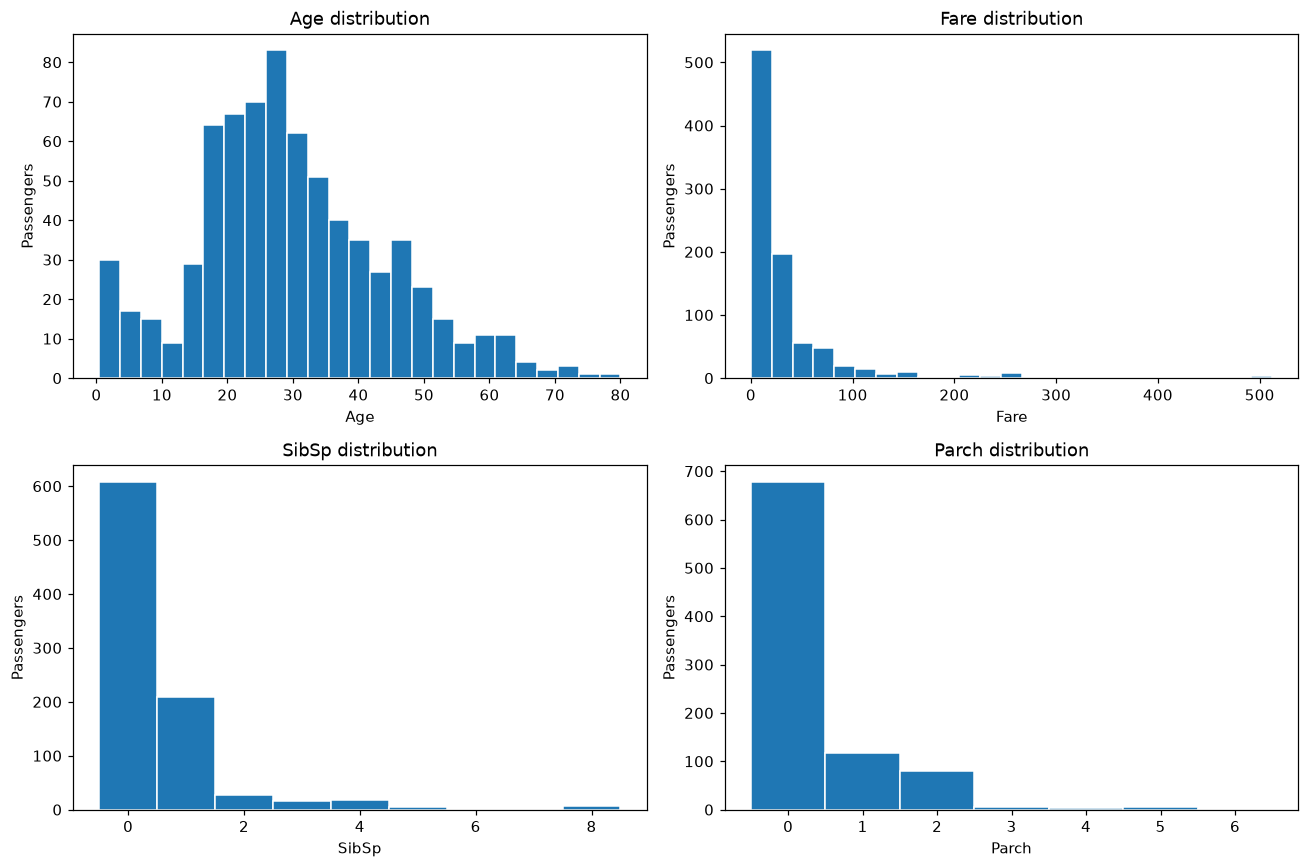

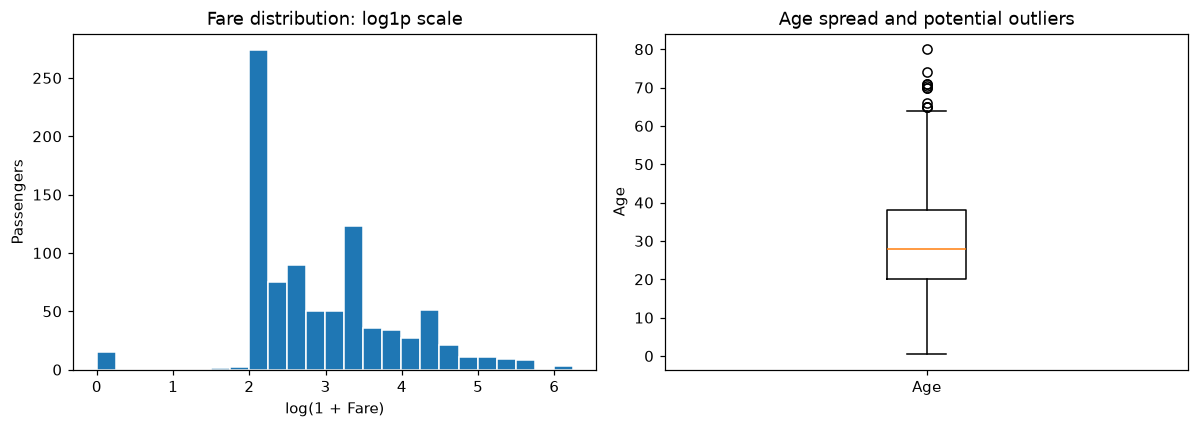

In [46]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, numeric_features):
    values = stats_data[column].dropna()
    bins = np.arange(values.min() - 0.5, values.max() + 1.5) if column in ["SibSp", "Parch"] else 25
    ax.hist(values, bins=bins, edgecolor="white")
    ax.set(title=f"{column} distribution", xlabel=column, ylabel="Passengers")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(np.log1p(stats_data["Fare"]), bins=25, edgecolor="white")
axes[0].set(title="Fare distribution: log1p scale", xlabel="log(1 + Fare)", ylabel="Passengers")
axes[1].boxplot([stats_data["Age"].dropna()], tick_labels=["Age"])
axes[1].set(title="Age spread and potential outliers", ylabel="Age")
plt.tight_layout()
plt.show()


Sex
        count  percent
Sex                   
male      577    64.76
female    314    35.24
Pclass
        count  percent
Pclass                
1         216    24.24
2         184    20.65
3         491    55.11
Embarked
          count  percent
Embarked                
S           644    72.28
C           168    18.86
Q            77     8.64
Missing       2     0.22


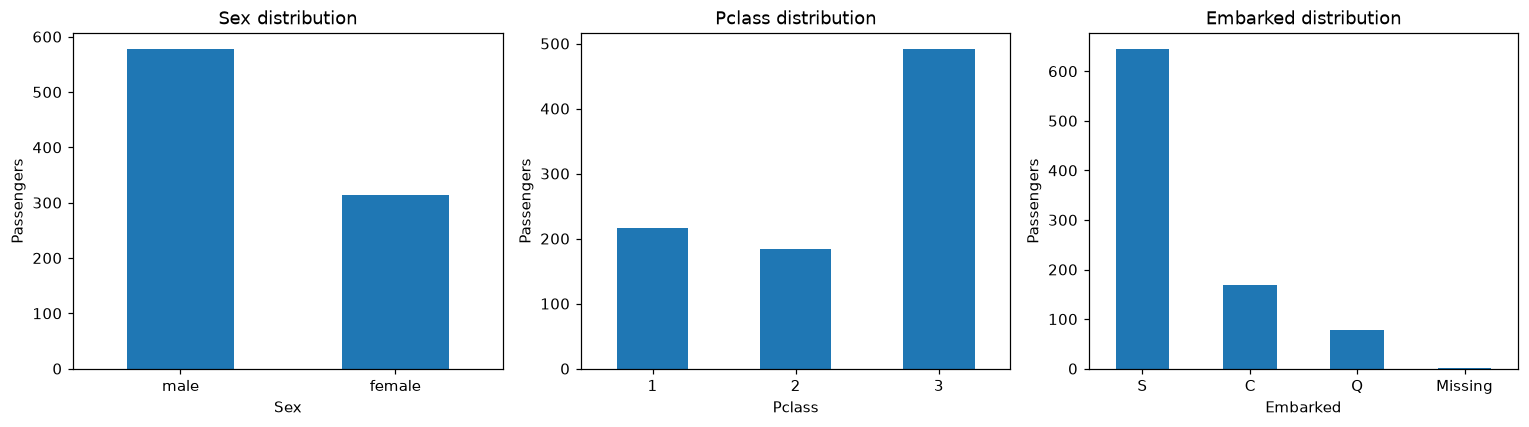

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, column in zip(axes, ["Sex", "Pclass", "Embarked"]):
    counts = stats_data[column].fillna("Missing").value_counts() if column != "Pclass" else stats_data[column].value_counts().sort_index()
    print(column)
    print(pd.DataFrame({"count": counts, "percent": (counts / len(stats_data) * 100).round(2)}))
    counts.plot.bar(ax=ax, rot=0)
    ax.set(title=f"{column} distribution", ylabel="Passengers")
plt.tight_layout()
plt.show()

Выживших 342 из 891 (38%), поэтому первый бейзлайн предсказывает самый частый класс (0.614 на отложенной выборке), а модели сравнивал на стратифицированной CV. `Fare` сильно скошена вправо (медиана 14, максимум 512), логарифм в экспериментах не применял. Возраст до 80 лет выглядит реальным, а не ошибкой.

        passengers  survived  survival_rate
Sex                                        
female         314       233       0.742038
male           577       109       0.188908


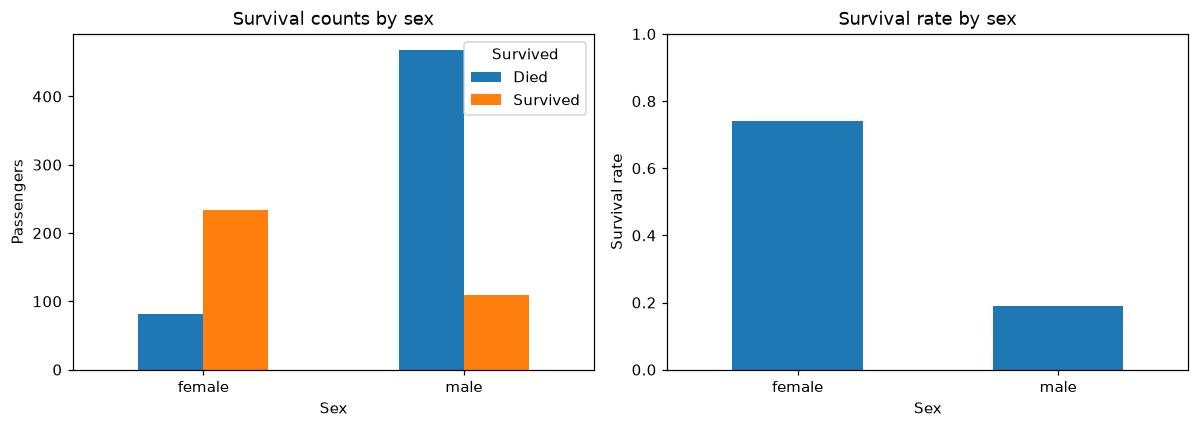

In [38]:
sex_summary = eda.groupby("Sex")["Survived"].agg(["count", "sum", "mean"])
print(sex_summary.rename(columns={"count": "passengers", "sum": "survived", "mean": "survival_rate"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
pd.crosstab(eda["Sex"], eda["Survived"]).rename(columns={0: "Died", 1: "Survived"}).plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Survival counts by sex", ylabel="Passengers")
sex_summary["mean"].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Survival rate by sex", ylabel="Survival rate", ylim=(0, 1))
plt.tight_layout()
plt.show()


        count       mean   median  min       max
Pclass                                          
1         216  84.154687  60.2875  0.0  512.3292
2         184  20.662183  14.2500  0.0   73.5000
3         491  13.675550   8.0500  0.0   69.5500


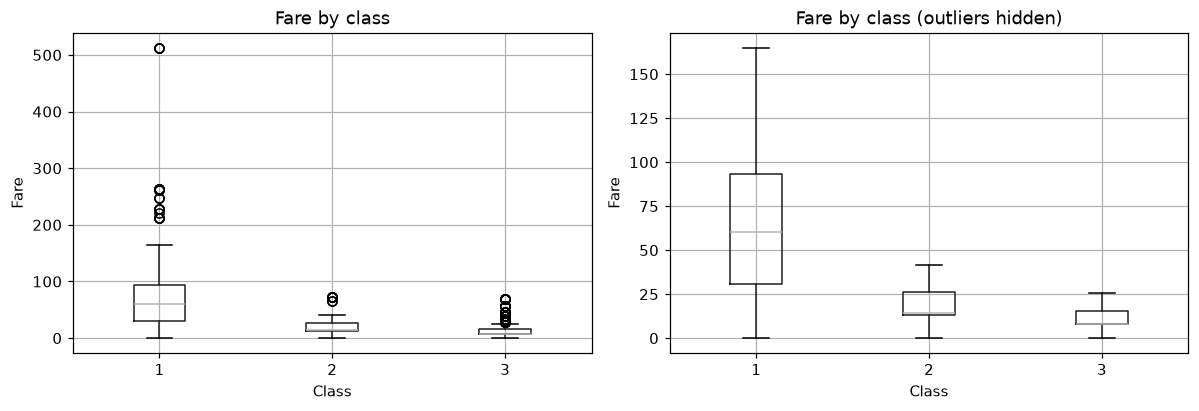

In [39]:
print(eda.groupby("Pclass")["Fare"].agg(["count", "mean", "median", "min", "max"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
eda.boxplot(column="Fare", by="Pclass", ax=axes[0])
axes[0].set(title="Fare by class", xlabel="Class", ylabel="Fare")
eda.boxplot(column="Fare", by="Pclass", showfliers=False, ax=axes[1])
axes[1].set(title="Fare by class (outliers hidden)", xlabel="Class", ylabel="Fare")
fig.suptitle("")
plt.tight_layout()
plt.show()


Женщины выживали в 74% случаев, мужчины в 19%, поэтому `Sex` есть во всех версиях как 0/1. `Fare` растёт с классом (медианы 60 / 14 / 8), но внутри класса сильно различается, поэтому оставил оба признака. Во второй версии логистической регрессии проверил one-hot для `Pclass`, чтобы не предполагать одинаковый шаг логита между классами.

Cabin recorded:
            count      mean
CabinKnown                 
False         687  0.299854
True          204  0.666667
Deck:
         count      mean
Deck                    
A           15  0.466667
B           47  0.744681
C           59  0.593220
D           33  0.757576
E           32  0.750000
F           13  0.615385
G            4  0.500000
T            1  0.000000
Unknown    687  0.299854
Cabin recorded by class (row proportions):
CabinKnown     False     True 
Pclass                        
1           0.185185  0.814815
2           0.913043  0.086957
3           0.975560  0.024440


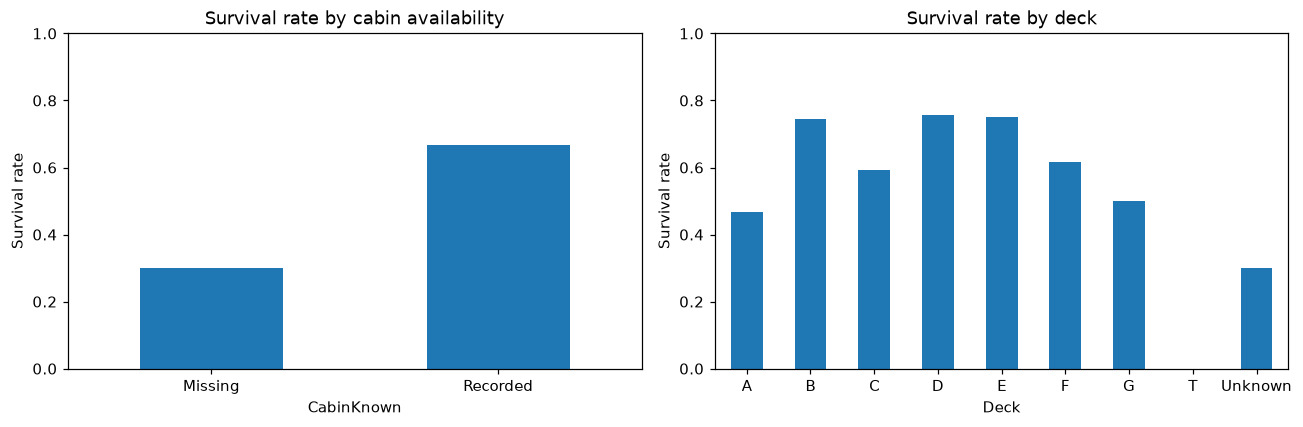

In [ ]:
eda["CabinKnown"] = eda["Cabin"].notna()
eda["Deck"] = eda["Cabin"].str.extract(r"([A-Za-z])", expand=False).str.upper().fillna("Unknown")
cabin_summary = eda.groupby("CabinKnown")["Survived"].agg(["count", "mean"])
deck_summary = eda.groupby("Deck")["Survived"].agg(["count", "mean"])
print("Cabin recorded:")
print(cabin_summary)
print("Deck:")
print(deck_summary)
print("Cabin recorded by class (row proportions):")
print(pd.crosstab(eda["Pclass"], eda["CabinKnown"], normalize="index"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cabin_summary["mean"].rename(index={False: "Missing", True: "Recorded"}).plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Survival rate by cabin availability", ylabel="Survival rate", ylim=(0, 1))
deck_summary["mean"].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Survival rate by deck", ylabel="Survival rate", ylim=(0, 1))
plt.tight_layout()
plt.show()


              count      mean
AgeGroup                     
[0.0, 12.0)      68  0.573529
[12.0, 18.0)     45  0.488889
[18.0, 30.0)    271  0.350554
[30.0, 45.0)    215  0.423256
[45.0, 60.0)     89  0.404494
[60.0, inf)      26  0.269231
Missing age:
       count      mean
Age                   
False    714  0.406162
True     177  0.293785


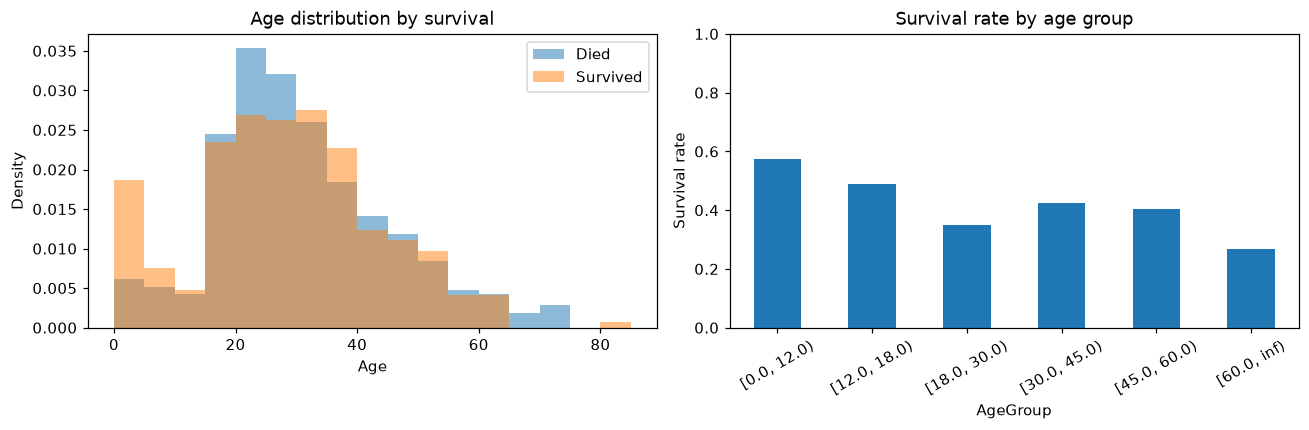

In [41]:
age_bins = [0, 12, 18, 30, 45, 60, np.inf]
eda["AgeGroup"] = pd.cut(eda["Age"], bins=age_bins, right=False)
age_summary = eda.groupby("AgeGroup", observed=True)["Survived"].agg(["count", "mean"])
print(age_summary)
print("Missing age:")
print(eda.groupby(eda["Age"].isna())["Survived"].agg(["count", "mean"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for survived, label in [(0, "Died"), (1, "Survived")]:
    axes[0].hist(eda.loc[eda["Survived"].eq(survived), "Age"].dropna(), bins=np.arange(0, 86, 5), alpha=0.5, density=True, label=label)
axes[0].set(title="Age distribution by survival", xlabel="Age", ylabel="Density")
axes[0].legend()
age_summary["mean"].plot.bar(ax=axes[1], rot=30)
axes[1].set(title="Survival rate by age group", ylabel="Survival rate", ylim=(0, 1))
plt.tight_layout()
plt.show()


Каюта записана у 23% пассажиров, и с записью выживали чаще (66,7% против 30,0%). Но запись есть у 81% первого класса и только у 2–9% остальных, поэтому `cabin_known` во многом повторяет `Pclass`. Палубы не использовал: в каждой меньше 60 наблюдений. При неизвестном возрасте выживаемость ниже (29,4% против 40,6%), поэтому к медиане добавил `age_missing`. Сам возраст влияет нелинейно: заметно выше доля выживших только у детей до 12 лет (57%).

Family size:
            count      mean
FamilySize                 
1             537  0.303538
2             161  0.552795
3             102  0.578431
4              29  0.724138
5              15  0.200000
6              22  0.136364
7              12  0.333333
8               6  0.000000
11              7  0.000000
Travelling alone:
         count      mean
IsAlone                 
False      354  0.505650
True       537  0.303538


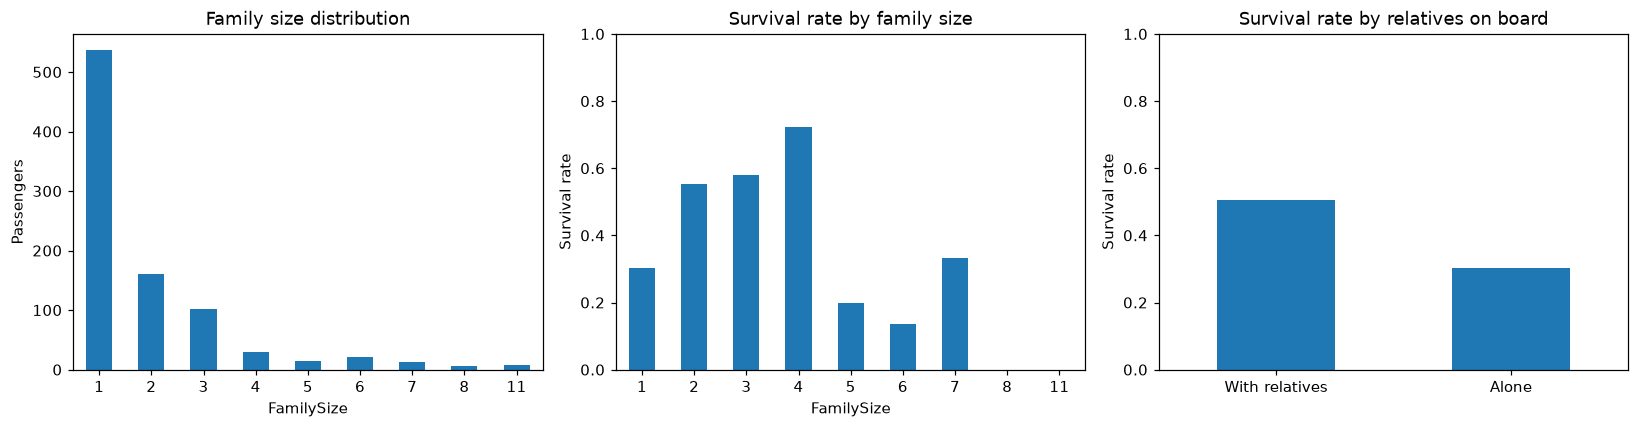

In [42]:
eda["FamilySize"] = eda["SibSp"] + eda["Parch"] + 1
eda["IsAlone"] = eda["FamilySize"].eq(1)
family_summary = eda.groupby("FamilySize")["Survived"].agg(["count", "mean"])
alone_summary = eda.groupby("IsAlone")["Survived"].agg(["count", "mean"])
print("Family size:")
print(family_summary)
print("Travelling alone:")
print(alone_summary)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
family_summary["count"].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Family size distribution", ylabel="Passengers")
family_summary["mean"].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Survival rate by family size", ylabel="Survival rate", ylim=(0, 1))
alone_summary["mean"].rename(index={False: "With relatives", True: "Alone"}).plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Survival rate by relatives on board", ylabel="Survival rate", ylim=(0, 1), xlabel="")
plt.tight_layout()
plt.show()


Семьи из 2–4 человек выживали чаще одиночек (55–72% против 30%), а начиная с 5 человек доля падает до 0–33%. Поэтому в `logreg_baseline_fe_v2` заменил `SibSp` и `Parch` группами по размеру семьи: один, 2–4, 5 и больше. Крупных семей всего 62, поэтому оценка для них шумная.

Ticket prefixes:
              count      mean
TicketPrefix                 
NONE            661  0.384266
PC               60  0.650000
CA               41  0.341463
A                28  0.071429
STONO            18  0.444444
SOTONOQ          15  0.133333
SCPARIS          11  0.454545
WC               10  0.100000
SOC               6  0.166667
C                 5  0.400000
FCC               5  0.800000
LINE              4  0.250000
SOPP              3  0.000000
WEP               3  0.333333
PP                3  0.666667
SCAH              2  0.500000
PPP               2  0.500000
SOTONO            2  0.000000
SWPP              2  1.000000
AS                1  0.000000
SCAHBASLE         1  1.000000
SCOW              1  0.000000
SC                1  1.000000
SOP               1  0.000000
FC                1  0.000000
SP                1  0.000000
FA                1  0.000000
CASOTON           1  0.000000
SCA               1  0.000000
First digit appearing in ticket:
                  co

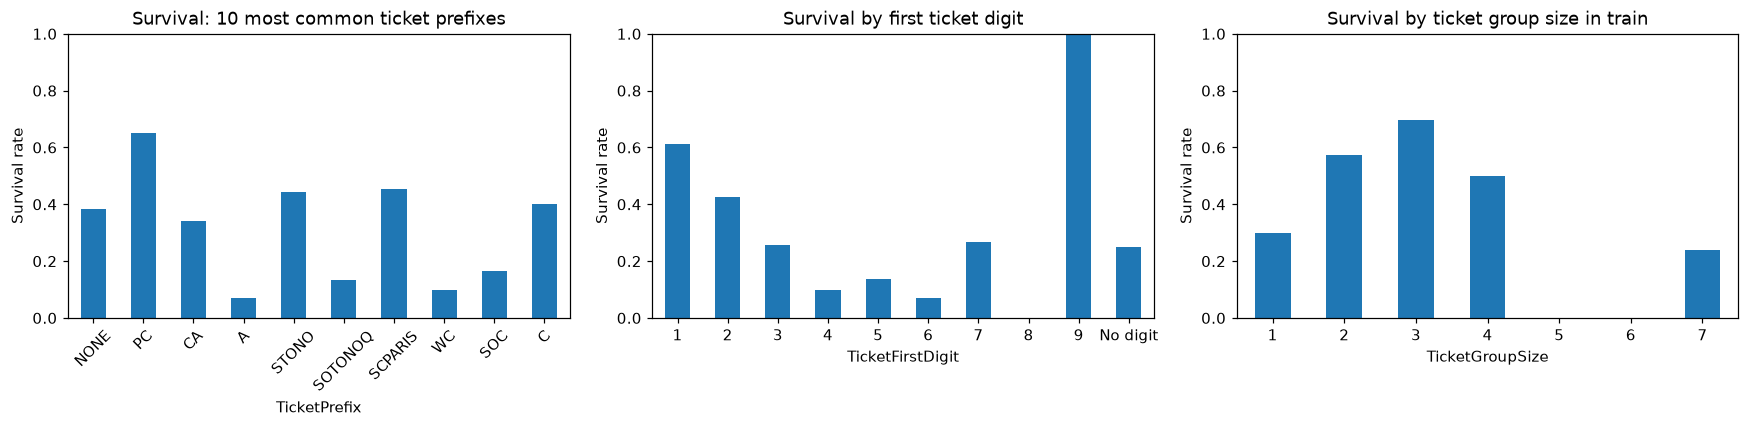

In [43]:
ticket = eda["Ticket"].str.upper().str.strip()
eda["TicketPrefix"] = ticket.str.replace(r"[0-9]+", "", regex=True).str.replace(r"[^A-Z]", "", regex=True).replace("", "NONE")
eda["TicketFirstDigit"] = ticket.str.extract(r"(\d)", expand=False).fillna("No digit")
eda["TicketGroupSize"] = ticket.map(ticket.value_counts())
prefix_summary = eda.groupby("TicketPrefix")["Survived"].agg(["count", "mean"]).sort_values("count", ascending=False)
digit_summary = eda.groupby("TicketFirstDigit")["Survived"].agg(["count", "mean"])
ticket_group_summary = eda.groupby("TicketGroupSize")["Survived"].agg(["count", "mean"])
print("Ticket prefixes:")
print(prefix_summary)
print("First digit appearing in ticket:")
print(digit_summary)
print("Passengers sharing a ticket within train:")
print(ticket_group_summary)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
prefix_summary.head(10)["mean"].plot.bar(ax=axes[0], rot=45)
axes[0].set(title="Survival: 10 most common ticket prefixes", ylabel="Survival rate", ylim=(0, 1))
digit_summary["mean"].plot.bar(ax=axes[1], rot=0)
axes[1].set(title="Survival by first ticket digit", ylabel="Survival rate", ylim=(0, 1))
ticket_group_summary["mean"].plot.bar(ax=axes[2], rot=0)
axes[2].set(title="Survival by ticket group size in train", ylabel="Survival rate", ylim=(0, 1))
plt.tight_layout()
plt.show()


`Ticket` не использовал: 681 уникальный билет на 891 пассажира, а у большинства префиксов мало наблюдений. Размер группы по билету повторяет картину размера семьи (2–4 выше, 5+ ниже), поэтому вряд ли добавил бы много к `FamilyGroup`.

          count      mean
Embarked                 
C           168  0.553571
Q            77  0.389610
S           644  0.336957
NaN           2  1.000000
Class proportions by port:
Pclass           1         2         3
Embarked                              
C         0.505952  0.101190  0.392857
Q         0.025974  0.038961  0.935065
S         0.197205  0.254658  0.548137
Survival rate by port and class:
Pclass           1         2         3
Embarked                              
C         0.694118  0.529412  0.378788
Q         0.500000  0.666667  0.375000
S         0.582677  0.463415  0.189802


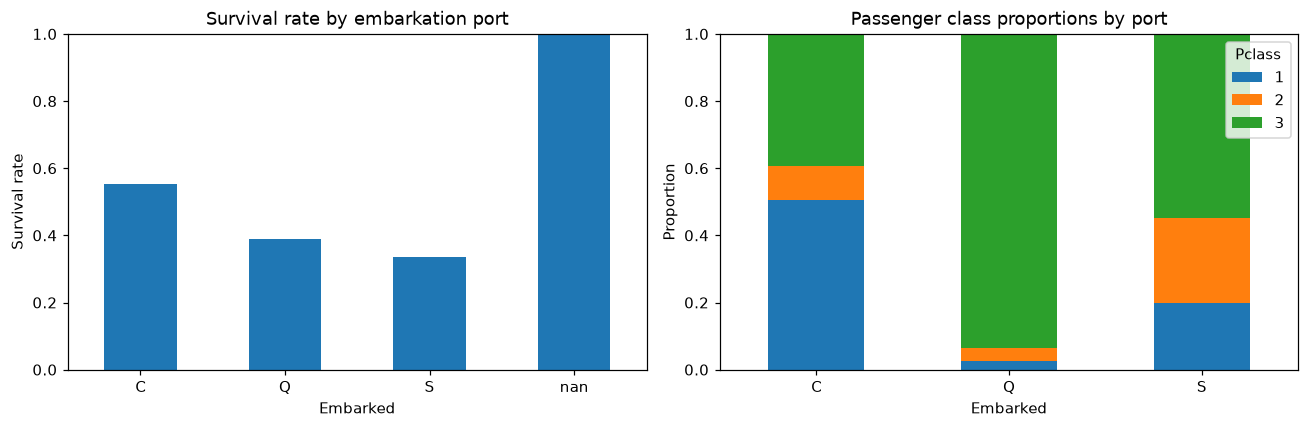

In [44]:
embarked_summary = eda.groupby("Embarked", dropna=False)["Survived"].agg(["count", "mean"])
print(embarked_summary)
print("Class proportions by port:")
print(pd.crosstab(eda["Embarked"], eda["Pclass"], normalize="index"))
print("Survival rate by port and class:")
print(eda.pivot_table(index="Embarked", columns="Pclass", values="Survived", aggfunc="mean"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
embarked_summary["mean"].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Survival rate by embarkation port", ylabel="Survival rate", ylim=(0, 1))
pd.crosstab(eda["Embarked"], eda["Pclass"], normalize="index").plot.bar(stacked=True, ax=axes[1], rot=0)
axes[1].set(title="Passenger class proportions by port", ylabel="Proportion", ylim=(0, 1))
plt.tight_layout()
plt.show()


По портам выживаемость: C 55%, Q 39%, S 34%. Частично это эффект класса: в C половина пассажиров из первого класса. Но в третьем классе S тоже заметно ниже (19% против 38% у C и Q), поэтому `Embarked` оставил и закодировал one-hot. Оба пассажира с пропущенным портом выжили, но двух наблюдений мало для выводов: в первой версии заполнял модой по обучающему фолду, во второй проверил категорию `Unknown`.

### Что дали изменения

В `logreg_baseline_fe_v2` все изменения проверены вместе: группы семьи, `cabin_known`, `age_missing`, one-hot для класса и `Unknown` для порта. CV выросла с 0.79687 до 0.81595, а public снизился с 0.76555 до 0.75837, так что рост CV на тесте не подтвердился, а вклад отдельных признаков не выделить. В `decision_tree_v2_optuna` без трёх новых признаков CV почти не изменилась (0.82043 -> 0.82153), public тот же (0.78229): пользы от них для дерева не видно. И в целом дальше не использовал эти признаки, так как для линейной модели они не дали прироста на паблике, а более сложные модели размер семьи могут найти сами по SibSp и Parch, cabin_known и так во многом повторяет Pclass. Хотя конечно дальше стоит поисследовать данные и поискать более мощные зависимости для создания новых фичей. Но на данном этапе решил остановиться, дабы не закапываться дальше.